# IRWA Final Project — Part 2: Indexing and Evaluation

In this notebook we build an inverted index over the fashion products dataset, answer **conjunctive (AND) queries** and rank the results with **TF-IDF and cosine similarity**.

Run the cells in order from `project_progress/part_2/`. The dataset must be in `data/` at the repository root.

In [1]:
# Install the required packages (only needed the first time; restart the kernel afterwards)
%pip install nltk pandas numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: C:\Users\farit\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 0. Data loading and preprocessing (reused from Part 1)

The preprocessing is the same as in Part 1, without changes: lowercase, alphanumeric tokens, English stop-word removal and Porter stemming. Queries go through the **same** function, so query terms and index terms always match.

In [2]:
# Reused code from Part 1

from pathlib import Path
from collections import Counter, defaultdict
import json
import math
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 100)  # show full product titles in the tables

nltk.download("stopwords", quiet=True, raise_on_error=True)
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

ROOT_DIR = Path.cwd().parent.parent
DATA_PATH = ROOT_DIR / "data" / "fashion_products_dataset.json"


# Same preprocessing as Part 1: lowercase, alphanumeric tokens, stopword removal, Porter stemming
def preprocess_text(text):
    if not text:
        return []
    tokens = re.findall(r"[a-z0-9]+", text.lower())
    return [stemmer.stem(t) for t in tokens if t not in stop_words]


# Flatten the list of {key: value} product details into one string (Part 1)
def product_details_to_text(product_details):
    return " ".join(f"{k} {v}" for detail in product_details for k, v in detail.items() if v is not None)


# Load the dataset and add the processed tokens of title, description and product details to each product
def load_and_preprocess(path=DATA_PATH):
    with open(path, "r") as f:
        products = json.load(f)

    # Each field is tokenized separately, so later we can decide which fields to index
    for p in products:
        p["title_tokens"] = preprocess_text(p["title"])
        p["description_tokens"] = preprocess_text(p["description"])
        p["product_details_tokens"] = preprocess_text(product_details_to_text(p["product_details"]))

    return products


products = load_and_preprocess()
print(f"Products loaded and preprocessed: {len(products):,}")

Products loaded and preprocessed: 28,080


## 1. Indexing

### 1.1 Inverted index

The inverted index maps every term to the list of products (`pid`) that contain it: `{term: [pid_1, pid_2, ...]}`.

**Indexed fields:** title, description and product details. These are the fields that describe the product itself (type, colour, fabric, fit…). Brand, seller and category are not indexed as free text in this part.

In [3]:
# Index terms of a product: title + description + product details tokens
def get_terms(product):
    return product["title_tokens"] + product["description_tokens"] + product["product_details_tokens"]


# Build the inverted index: term -> list of pids that contain the term
def create_index(products):
    index = defaultdict(list)

    # set(): a product is added only once to the list of each term, even if the term is repeated
    for p in products:
        for term in set(get_terms(p)):
            index[term].append(p["pid"])

    return index


# Build the index ONCE and reuse it in the rest of the notebook
index = create_index(products)
titles = {p["pid"]: p["title"] for p in products}  # pid -> title, to display results

print(f"Terms in the index (vocabulary size): {len(index):,}")
print("Sample terms:", list(index.keys())[:10])
print(f"Products containing 'jean': {len(index['jean']):,}")

Terms in the index (vocabulary size): 20,426
Sample terms: ['design', 'style', 'rich', 'give', 'india', 'friendli', 'year', 'fabric', 'itch', 'great']
Products containing 'jean': 2,437


### 1.2 Conjunctive (AND) search

A product is returned only if it contains **all** the query terms, so the result is the **intersection** of the postings lists of the query terms. We start from the shortest list, which makes the intersection faster and lets us stop as soon as it becomes empty.

In [4]:
# AND search: return the set of pids that contain ALL the query terms
def search_and(query, index):
    terms = preprocess_text(query)  # the query is preprocessed exactly like the documents
    if not terms:
        return set()

    # Postings lists of the query terms, from the shortest to the longest
    postings = sorted((set(index.get(term, [])) for term in set(terms)), key=len)

    # Intersect them one by one; if the result becomes empty no document can match, so we stop
    docs = postings[0]
    for posting in postings[1:]:
        docs &= posting
        if not docs:
            break

    return docs


results = search_and("men slim jeans blue", index)
print(f"AND results for 'men slim jeans blue': {len(results)} products")
for pid in list(results)[:5]:
    print(f"  {pid}: {titles[pid]}")

AND results for 'men slim jeans blue': 222 products
  JEAFS2JZXS5E2TKH: Slim Men Blue Jeans
  JEAFUZXSQQHZXRYM: Super Skinny Men Blue Jeans
  JEAFUZXUGWXHUF5F: Jogger Fit Men Blue Jeans
  JEAFSKYHZHSZZC9S: Slim Men Blue Jeans
  JEAEKZFGQSYRFV9K: Slim Men Blue Jeans


### 1.3 Test queries

The dataset contains almost only clothing (Part 1 EDA), so the queries are clothing searches. To choose them we looked at the most frequent terms in the product titles and combined popular terms (gender, colour, product type) with more specific ones (fabric, pattern, usage):

| Query | Why |
|---|---|
| men black polo shirt | very popular terms (men, black, polo, shirt) — a common, easy search |
| women printed cotton kurta | a specific ethnic product with pattern and fabric |
| grey track pants | no gender: men's and women's products are both valid |
| men denim jacket | "denim" is often only in the fabric field (product details), not in the title |
| women yoga pants | a usage word ("yoga") that rarely appears in titles |

In [5]:
# Most frequent terms in the product titles (term popularity)
title_counts = Counter()
for p in products:
    title_counts.update(p["title_tokens"])
pd.DataFrame(title_counts.most_common(15), columns=["term", "count"]).T # T = transposed

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
term,shirt,women,men,neck,solid,round,print,pack,blue,fit,black,casual,slim,polo,collar
count,15838,13146,13060,11952,9246,8301,8123,4839,4378,3923,3503,2927,2893,2668,2427


In [6]:
#choosen queries for testing the AND search
test_queries = [
    "men black polo shirt",
    "women printed cotton kurta",
    "grey track pants",
    "men denim jacket",
    "women yoga pants",
]

# Check that every query returns results with the AND search
for query in test_queries:
    print(f"{query!r:32} terms={preprocess_text(query)} -> {len(search_and(query, index))} results")

'men black polo shirt'           terms=['men', 'black', 'polo', 'shirt'] -> 229 results
'women printed cotton kurta'     terms=['women', 'print', 'cotton', 'kurta'] -> 42 results
'grey track pants'               terms=['grey', 'track', 'pant'] -> 327 results
'men denim jacket'               terms=['men', 'denim', 'jacket'] -> 73 results
'women yoga pants'               terms=['women', 'yoga', 'pant'] -> 19 results


The chart below shows the 15 most frequent title terms; the ones used in our test queries are highlighted (Figure 1 of the report).

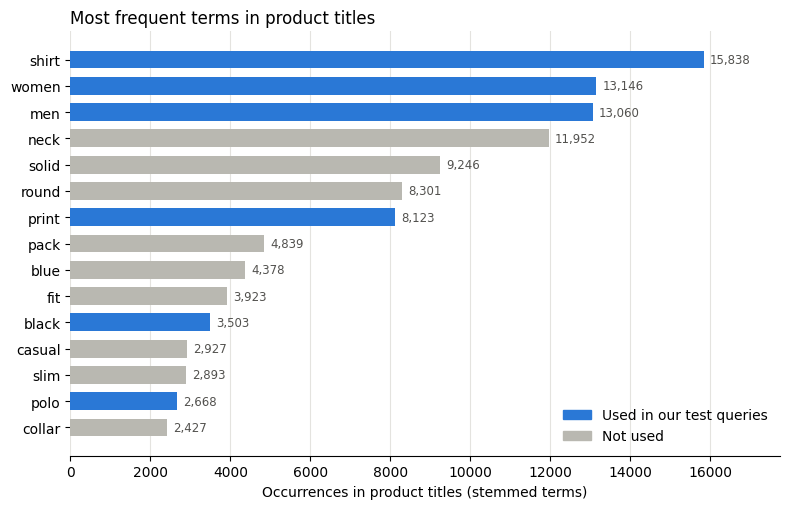

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Terms of the test queries, preprocessed like the documents
query_terms = {term for query in test_queries for term in preprocess_text(query)}

# Top 15 title terms, from the most to the least frequent (bottom to top in the chart)
top_terms = title_counts.most_common(15)[::-1]
terms = [term for term, _ in top_terms]
counts = [count for _, count in top_terms]
colors = ["#2a78d6" if term in query_terms else "#b9b8b1" for term in terms]

fig, ax = plt.subplots(figsize=(8, 5.2))
bars = ax.barh(terms, counts, color=colors, height=0.68)

# Value at the end of each bar
for bar, count in zip(bars, counts):
    ax.text(count + 150, bar.get_y() + bar.get_height() / 2, f"{count:,}", va="center", fontsize=8.5, color="#52514e")

ax.set_xlabel("Occurrences in product titles (stemmed terms)")
ax.set_title("Most frequent terms in product titles", loc="left")
ax.xaxis.grid(True, color="#e4e3df")
ax.set_axisbelow(True)
ax.set_xlim(0, max(counts) * 1.12)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(handles=[Patch(color="#2a78d6", label="Used in our test queries"), Patch(color="#b9b8b1", label="Not used")],
          loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig("1.3_top_title_terms.png", dpi=170)
plt.show()

### 1.4 Ranking with TF-IDF and cosine similarity

- **TF** (term frequency): occurrences of the term in the product / total terms of the product.
- **IDF** (inverse document frequency): `idf = log(N / df)`, where N is the number of products and df the number of products that contain the term. Rare terms (e.g. *kurta*) get a high idf; very common terms (e.g. *shirt*) a low one.
- **Weight = TF × IDF**, for the products and for the query.
- **Cosine similarity** between the query vector and each product vector; the products are sorted from highest to lowest similarity.

Only the products returned by the AND search are ranked.

In [8]:
# TF of every product: pid -> {term: count / total terms of the product}
def TF(products):
    tf = {}
    for p in products:
        terms = get_terms(p)            # All terms of the product (title + description + details)
        total_terms = len(terms)        # Total number of terms in the product
        term_counts = Counter(terms)    # Occurrences of each term in the product

        # Relative frequency of each term; products without any term get an empty vector
        if total_terms > 0:
            tf[p["pid"]] = {term: count / total_terms for term, count in term_counts.items()}
        else:
            tf[p["pid"]] = {}

    return tf


# IDF of every term: log(N / df); df is the length of the term's postings list in the index
def IDF(index, n_products):
    idf = {}

    for term, pids in index.items():
        df = len(pids)
        idf[term] = math.log(n_products / df)

    return idf

# TF-IDF weights of every product: pid -> {term: tf * idf}
def TFxIDF(tf, idf):
    tfidf = {}

    for pid, term_tf in tf.items():
        tfidf[pid] = {}

        # Weight of each term = FREQUENCY in the product * RARENESS in the collection
        for term, tf_value in term_tf.items():
            tfidf[pid][term] = tf_value * idf[term]

    return tfidf

# Euclidean norm of a sparse vector stored as a dict
def vector_norm(vector):
    sum_of_squares = 0.0

    for value in vector.values():
        sum_of_squares += value ** 2

    return math.sqrt(sum_of_squares)


# Compute everything ONCE. The product norms are precomputed because the cosine
# similarity needs them for every query, and they never change
tf = TF(products)
idf = IDF(index, len(products))
tfidf = TFxIDF(tf, idf)

tfidf_norms = {}
for pid, vector in tfidf.items():
    tfidf_norms[pid] = vector_norm(vector)

print(f"idf('shirt') = {idf['shirt']:.3f}   idf('kurta') = {idf['kurta']:.3f}")

idf('shirt') = 0.515   idf('kurta') = 3.575


In [9]:
# TF-IDF vector of the query (same TF definition as for the products)
def query_vector(query, idf):
    # Preprocess the query like the documents and keep only the terms that exist in the index
    terms = []
    for term in preprocess_text(query):
        if term in idf:
            terms.append(term)

    if len(terms) == 0:
        return {}

    total_terms = len(terms)            # Total number of terms in the query
    term_counts = Counter(terms)        # Occurrences of each term in the query

    # Weight of each query term = relative frequency in the query * idf
    q_vector = {}
    for term, count in term_counts.items():
        q_vector[term] = (count / total_terms) * idf[term]

    return q_vector


# Cosine similarity between the query vector and the TF-IDF vector of product pid
def cosine_similarity(q_vector, pid):
    d_vector = tfidf[pid]               # TF-IDF vector of the product

    # Dot product: only the query terms contribute (every other query weight is 0)
    dot_product = 0.0
    for term, q_weight in q_vector.items():
        d_weight = d_vector.get(term, 0.0)   # 0 if the product does not contain the term
        dot_product += q_weight * d_weight

    # Divide by both norms; the product norm was precomputed
    norms = vector_norm(q_vector) * tfidf_norms[pid]
    if norms == 0:
        return 0.0

    return dot_product / norms


# AND search + TF-IDF ranking: list of (pid, score) sorted by descending cosine similarity
def search_tfidf(query, index, idf):
    # Only the products that contain ALL the query terms are ranked
    docs = search_and(query, index)
    q_vector = query_vector(query, idf)

    # Score every candidate product
    scores = []
    for pid in docs:
        score = cosine_similarity(q_vector, pid)
        scores.append((pid, score))

    # Sort from the most to the least similar product
    scores.sort(key=lambda item: item[1], reverse=True)
    return scores


# Show the top-k ranked products of a query as a table
def show_top(query, k=10):
    ranking = search_tfidf(query, index, idf)
    print(f"Query: {query!r} -> {len(ranking)} results")

    # One row per product: position, pid, score and title
    rows = []
    position = 1
    for pid, score in ranking[:k]:
        rows.append({"rank": position, "pid": pid, "score": round(score, 3), "title": titles[pid]})
        position += 1

    return pd.DataFrame(rows)

In [10]:
for query in test_queries:
    display(show_top(query))

Query: 'men black polo shirt' -> 229 results


,rank,pid,score,title
0,1,TSHFYMXPFSYGNYKB,0.859,Solid Men Polo Neck Black T-Shirt
1,2,TSHFWYV9GJ8FWQGG,0.711,Solid Men Polo Neck Black T-Shirt
2,3,TSHFZQBG3J5GREG2,0.688,Printed Men Polo Neck Black T-Shirt
3,4,TSHFGQGQZPVZHD2S,0.659,Solid Men Polo Neck Black T-Shirt
4,5,TSHEKHHHHDVZCWRD,0.641,Solid Men Polo Neck Black T-Shirt
5,6,TSHFV8YFJGXRZESG,0.635,Printed Men Polo Neck Black T-Shirt
6,7,TSHFZQ9RWFAN3U6J,0.630,Printed Men Polo Neck Black T-Shirt
7,8,TSHFDFHTKZZ4ETDC,0.609,Striped Men Polo Neck Black T-Shirt
8,9,TSHFYZ977AHKXDMX,0.605,Solid Men Polo Neck Black T-Shirt
9,10,TSHFPNX6GZXMAEC5,0.601,Solid Men Polo Neck Black T-Shirt


Query: 'women printed cotton kurta' -> 42 results


,rank,pid,score,title
0,1,KTAF5SD3WHM2V9HZ,0.627,Women Printed Cotton Blend Straight Kurta (Orange)
1,2,KTAFD3ZMEMREHQHS,0.581,Women Printed Cotton Blend Straight Kurta (Orange)
2,3,KTAFD3ZMPXPC3GE4,0.581,Women Printed Cotton Blend Straight Kurta (Orange)
3,4,KTAFD3ZMZSMMHB5C,0.581,Women Printed Cotton Blend Straight Kurta (Orange)
4,5,KTAFD3ZMWMWFHWHH,0.581,Women Printed Cotton Blend Straight Kurta (Orange)
5,6,KTAFDVG4YZBS44WT,0.560,"Women Printed Cotton Blend Straight Kurta (Blue, Orange)"
6,7,KTAFZCK5RGNECHHH,0.557,Women Printed Cotton Linen Blend Straight Kurta (Blue)
7,8,KTAFZ9KFEAFVMWFN,0.553,Women Polka Print Cotton Blend A-line Kurta (White)
8,9,KTAFZCH5BCNAFZJ6,0.540,Women Printed Cotton Linen Blend Straight Kurta (White)
9,10,KTAFBCFZCBYFGW8H,0.539,Women Printed Cotton Blend Straight Kurta (Multicolor)


Query: 'grey track pants' -> 327 results


,rank,pid,score,title
0,1,TKPFZG64NDH5W4UY,0.899,Striped Men Grey Track Pants
1,2,TKPFZZB2YWMDFBSB,0.865,Solid Women Grey Track Pants
2,3,TKPFZZB24KX9MA8F,0.865,Solid Men Grey Track Pants
3,4,TKPFWJSKDGQVBQTJ,0.840,Solid Men Grey Track Pants
4,5,TKPFZY4YKZ5TKYY3,0.809,"Solid Women Grey, Blue Track Pants"
5,6,TKPFXS5ZAB7BZM6N,0.809,"Solid Women Grey, Blue Track Pants"
6,7,TKPFXS6Z6HVHG9HW,0.809,"Solid Women Grey, Blue Track Pants"
7,8,TKPFXS5ZEYHHHCHQ,0.805,"Solid Women Grey, Black Track Pants"
8,9,TKPFXNPJW43UVTQX,0.804,Solid Women Grey Track Pants
9,10,TKPFXNPJBKUAYEME,0.791,"Solid Men Blue, Grey Track Pants"


Query: 'men denim jacket' -> 73 results


,rank,pid,score,title
0,1,JCKFZJWZNCGGZGSE,0.920,Full Sleeve Washed Men Denim Jacket
1,2,JCKFZJWZBZCCTYXM,0.920,Full Sleeve Washed Men Denim Jacket
2,3,JCKFZZN6AWQZ8FC2,0.895,Full Sleeve Solid Men Denim Jacket
3,4,JCKFURYWGYKVKFH3,0.661,Full Sleeve Solid Men Denim Jacket
4,5,JCKFVDPW4WNPBGS2,0.658,Full Sleeve Solid Men Denim Jacket
5,6,JCKFWC5YZKFWXGEB,0.658,Full Sleeve Solid Men Denim Jacket
6,7,JCKFWC5YPXZG6S7F,0.652,Full Sleeve Solid Men Denim Jacket
7,8,JCKFYY97BC7KWPM4,0.651,Full Sleeve Solid Men Denim Jacket
8,9,JCKFWC5ZAF3BRTPA,0.630,Full Sleeve Solid Men Denim Jacket
9,10,JCKFXAKSEGEGGGEY,0.614,Full Sleeve Solid Men Jacket


Query: 'women yoga pants' -> 19 results


,rank,pid,score,title
0,1,TKPFYG7THT4SKNEA,0.253,Solid Women Black Track Pants
1,2,TKPFYCGPENXCPBYK,0.242,Solid Women Black Track Pants
2,3,TKPFY485BVMHNVFS,0.238,"Solid Women Black, Dark Blue Track Pants"
3,4,TKPFY485NTJM8AFP,0.238,"Solid Women Black, Dark Blue Track Pants"
4,5,TKPFWV6JX5UBSUGV,0.208,Solid Women Black Track Pants
5,6,TKPFWV6JRM6MBEXH,0.206,Solid Women Dark Blue Track Pants
6,7,TKPFWV6JCPGUZEBG,0.206,Solid Women Grey Track Pants
7,8,TKPFWGHYPNQYZNFW,0.181,Solid Women Blue Track Pants
8,9,TKPFZMVF5B2GKFNT,0.175,Solid Women Black Track Pants
9,10,TKPFZMUZRZFGZMKK,0.175,Solid Women Black Track Pants


## 2. Evaluation

### 2.1 Evaluation metrics

All the per-query metrics receive the same three inputs:

- `y_true`: the relevance label of each judged document (1 = relevant, 0 = not relevant)
- `y_score`: the score our search engine gives to each of those documents. If the AND search does **not** return a document, its score is `NaN`: it never appears in the top K, but it still counts as a relevant document that we should have found (for recall and for the ideal ranking of NDCG)
- `k`: the cut-off (we only look at the first K results)

With $rel_i \in \{0, 1\}$ the label of the document at position $i$ of our ranking, $R$ the total number of relevant judged documents and $Q$ the set of queries:

| Metric | Formula |
|---|---|
| Precision@K | $P@K = \dfrac{1}{K}\sum_{i=1}^{K} rel_i$ |
| Recall@K | $R@K = \dfrac{1}{R}\sum_{i=1}^{K} rel_i$ |
| Average Precision@K | $AP@K = \dfrac{\sum_{i=1}^{K} P@i \cdot rel_i}{\sum_{i=1}^{K} rel_i}$ |
| F1-Score@K | $F1@K = \dfrac{2 \cdot P@K \cdot R@K}{P@K + R@K}$ |
| Mean Average Precision | $MAP = \dfrac{1}{\lvert Q\rvert}\sum_{q \in Q} AP@K(q)$ |
| Mean Reciprocal Rank | $MRR = \dfrac{1}{\lvert Q\rvert}\sum_{q \in Q} \dfrac{1}{rank_q}$, where $rank_q$ is the position of the first relevant document (0 if none in the top K) |
| NDCG@K | $DCG@K = \sum_{i=1}^{K} \dfrac{2^{rel_i} - 1}{\log_2(i + 1)}$, $\quad NDCG@K = \dfrac{DCG@K}{IDCG@K}$ (IDCG = DCG of the ideal ranking) |

In [11]:
# Labels of the retrieved documents, sorted from the highest to the lowest score
def ranked_labels(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score, dtype=float)

    # Documents not returned by the AND search have score NaN: they are not part of the ranking
    retrieved = ~np.isnan(y_score)
    labels = y_true[retrieved]
    scores = y_score[retrieved]

    # Sort by descending score; "stable" keeps the original order when two scores are equal
    order = np.argsort(-scores, kind="stable")
    return labels[order]


# P@K: fraction of the top-K documents that are relevant
def precision_at_k(y_true, y_score, k=10):
    top_k = ranked_labels(y_true, y_score)[:k]
    relevant_in_top_k = np.sum(top_k == 1)
    return relevant_in_top_k / k


# R@K: fraction of all the relevant documents that appear in the top K
def recall_at_k(y_true, y_score, k=10):
    total_relevant = np.sum(np.asarray(y_true) == 1)
    if total_relevant == 0:
        return 0.0

    top_k = ranked_labels(y_true, y_score)[:k]
    relevant_in_top_k = np.sum(top_k == 1)
    return relevant_in_top_k / total_relevant


# F1@K: harmonic mean of P@K and R@K
def f1_at_k(y_true, y_score, k=10):
    precision = precision_at_k(y_true, y_score, k)
    recall = recall_at_k(y_true, y_score, k)

    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)

In [12]:
# AP@K: mean of the precision at every position (<= K) where there is a relevant document
def avg_precision_at_k(y_true, y_score, k=10):
    top_k = ranked_labels(y_true, y_score)[:k]

    # Walk down the ranking; each time we find a relevant document we store P@position
    relevant_found = 0
    precisions = []
    for position, label in enumerate(top_k, start=1):
        if label == 1:
            relevant_found += 1
            precisions.append(relevant_found / position)

    if len(precisions) == 0:
        return 0.0
    return np.mean(precisions)


# MAP@K: mean of the AP@K of all the queries; queries is a list of (y_true, y_score) pairs
def map_at_k(queries, k=10):
    ap_values = []
    for y_true, y_score in queries:
        ap_values.append(avg_precision_at_k(y_true, y_score, k))
    return np.mean(ap_values), ap_values

In [13]:
# RR@K: 1 / position of the first relevant document in the top K (0 if there is none)
def rr_at_k(y_true, y_score, k=10):
    top_k = ranked_labels(y_true, y_score)[:k]

    for position, label in enumerate(top_k, start=1):
        if label == 1:
            return 1 / position

    return 0.0


# MRR@K: mean of the reciprocal ranks of all the queries
def mrr_at_k(queries, k=10):
    rr_values = []
    for y_true, y_score in queries:
        rr_values.append(rr_at_k(y_true, y_score, k))
    return np.mean(rr_values), rr_values

In [14]:
# DCG@K: sum of the gains (2^rel - 1) of the top-K documents, discounted by log2(position + 1)
def dcg_at_k(y_true, y_score, k=10):
    top_k = ranked_labels(y_true, y_score)[:k].astype(float)

    dcg = 0.0
    for position, label in enumerate(top_k, start=1):
        gain = 2 ** label - 1
        discount = np.log2(position + 1)
        dcg += gain / discount

    return dcg


# NDCG@K: DCG@K of our ranking divided by the DCG@K of the ideal ranking
def ndcg_at_k(y_true, y_score, k=10):
    # Ideal ranking: ALL the judged documents sorted by their true label (relevant first)
    ideal_dcg = dcg_at_k(y_true, np.asarray(y_true, dtype=float), k)
    if ideal_dcg == 0:
        return 0.0

    return dcg_at_k(y_true, y_score, k) / ideal_dcg

In [15]:
# All the per-query metrics at cut-off K in one dictionary
def evaluate_query(y_true, y_score, k=10):
    return {
        f"P@{k}": precision_at_k(y_true, y_score, k),
        f"R@{k}": recall_at_k(y_true, y_score, k),
        f"AP@{k}": avg_precision_at_k(y_true, y_score, k),
        f"F1@{k}": f1_at_k(y_true, y_score, k),
        f"RR@{k}": rr_at_k(y_true, y_score, k),
        f"NDCG@{k}": ndcg_at_k(y_true, y_score, k),
    }


# Quick check on a toy example: 5 judged documents, the 4th one is not returned by the search
toy_true = [1, 0, 1, 1, 0]
toy_score = [0.9, 0.8, 0.4, np.nan, 0.1]
for metric, value in evaluate_query(toy_true, toy_score, k=3).items():
    print(f"{metric:8} {value:.3f}")

P@3      0.667
R@3      0.667
AP@3     0.833
F1@3     0.667
RR@3     1.000
NDCG@3   0.704


### 2.2 Evaluation using validation_labels.csv

**Query 1:** women full sleeve sweatshirt cotton

**Query 2:** men slim jeans blue

In [16]:
validation_queries = {
    1: "women full sleeve sweatshirt cotton",
    2: "men slim jeans blue"
}

In [17]:
validation_path = ROOT_DIR / "data" / "validation_labels.csv"

validation = pd.read_csv(validation_path)

print("Shape:", validation.shape)
print("Columns:", validation.columns.tolist())

display(validation.head())

Shape: (40, 4)
Columns: ['title', 'pid', 'query_id', 'labels']


,title,pid,query_id,labels
0,Full Sleeve Printed Women Sweatshirt,SWSFFVKBCQG5FHPF,1,1
1,Full Sleeve Striped Women Sweatshirt,SWSFJY5ZFHQ7HXKW,1,0
2,Full Sleeve Printed Women Sweatshirt,SWSFUY89NHMZHZPX,1,1
3,Full Sleeve Graphic Print Women Sweatshirt,SWSFXQ5YX6RZKHP4,1,1
4,Full Sleeve Solid Women Sweatshirt,JCKFTZBC3DMCVYXH,1,0


In [18]:
# Evaluate one validation query: returns (y_true, y_score) and stores its metrics in validation_results
def validate_query(query_id, query):
    # Relevance judgments of this query
    query_labels = validation[validation["query_id"] == query_id]

    # TF-IDF scores of our search engine; judged products not returned by the AND search get NaN
    ranked_results = search_tfidf(query, index, idf)
    score_lookup = dict(ranked_results)

    y_true = query_labels["labels"].astype(int).to_numpy()
    y_score = query_labels["pid"].map(score_lookup).to_numpy(dtype=float)

    # All the per-query metrics
    metrics = evaluate_query(y_true, y_score, k=K)
    validation_results.append({"query_id": query_id, **metrics})

    return y_true, y_score


K = 10
validation_results = []
validation_evaluations = []

for query_id, query in validation_queries.items():
    validation_evaluations.append(validate_query(query_id, query))

# MAP and MRR over the two validation queries
map_value, _ = map_at_k(validation_evaluations, k=K)
mrr_value, _ = mrr_at_k(validation_evaluations, k=K)

# Numeric results only
results_df = pd.DataFrame(validation_results).set_index("query_id")
results_df.loc["Mean", "MAP@10"] = map_value
results_df.loc["Mean", "MRR@10"] = mrr_value

display(results_df.style.format("{:.3f}", na_rep=""))

,P@10,R@10,AP@10,F1@10,RR@10,NDCG@10,MAP@10,MRR@10
query_id,,,,,,,,
1,1.000,0.769,1.000,0.870,1.000,1.000,,
2,0.600,0.600,0.915,0.600,1.000,0.706,,
Mean,,,,,,,0.958,1.000


**Precision@K and Recall@K for K = 1…20** on the two validation queries (Figure 4 of the report). It shows how the metrics change with the cut-off and where the ranking stops finding relevant products.

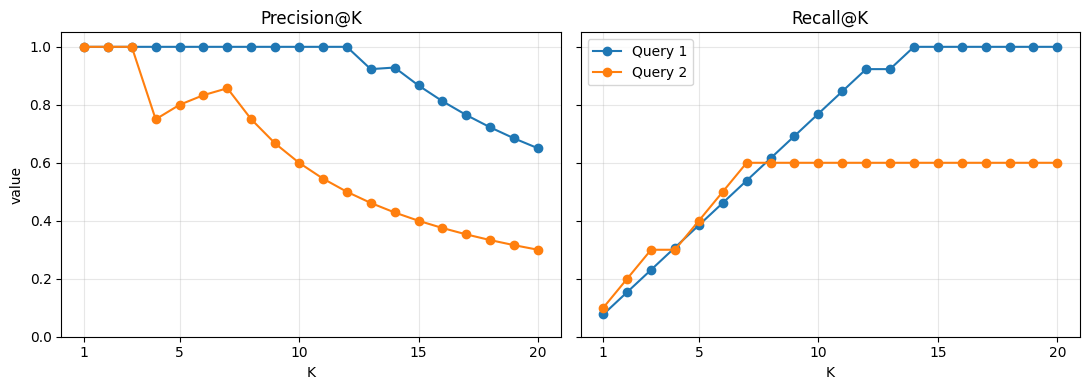

In [19]:
import matplotlib.pyplot as plt

ks = range(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

# One panel per metric, one line per validation query (validation_evaluations holds (y_true, y_score) per query)
for ax, (metric, name) in zip(axes, [(precision_at_k, "Precision@K"), (recall_at_k, "Recall@K")]):
    for query_id, (y_true, y_score) in zip(validation_queries, validation_evaluations):
        ax.plot(ks, [metric(y_true, y_score, k) for k in ks], marker="o", label=f"Query {query_id}")
    ax.set_title(name)
    ax.set_xlabel("K")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(alpha=0.3)

axes[0].set_ylabel("value")
axes[0].set_ylim(0, 1.05)
axes[1].legend()
plt.tight_layout()
plt.savefig("2.2_precision_recall_at_k.png", dpi=150)
plt.show()

### 2.3 Evaluation with manually assigned relevance judgments

Now we evaluate the five queries defined in Section 1.3 using manually assigned binary relevance labels.

We assign label 1 if the document is relevant to the query, or 0 otherwise.

The resulting relevance judgments are stored in custom_query_labels.csv.

In [20]:
POOL_SIZE = 20

labels_path = Path("custom_query_labels.csv")

products_by_pid = {p["pid"]: p for p in products}

rows = []

for query_id, query in enumerate(test_queries, start=1):

    # Existing AND search with TF-IDF ranking
    ranked_results = search_tfidf(query, index, idf)

    print(f"Query {query_id}: {query}")
    print(f"Retrieved documents: {len(ranked_results)}")

    # Select the top 20 results
    for rank, (pid, score) in enumerate(
        ranked_results[:POOL_SIZE], start=1
    ):

        product = products_by_pid[pid]

        rows.append({
            "query_id": query_id,
            "query": query,
            "pid": pid,
            "rank": rank,
            "title": product.get("title", ""),
            "description": product.get("description", ""),
            "product_details": str(
                product.get("product_details", "")
            ),
            "score": score,
            "labels": ""
        })

labeling_df = pd.DataFrame(rows)

# Avoid overwriting existing manual labels
if not labels_path.exists():
    labeling_df.to_csv(labels_path, index=False)
    print(f"Created: {labels_path}")
else:
    print(f"File already exists: {labels_path}")

Query 1: men black polo shirt
Retrieved documents: 229
Query 2: women printed cotton kurta
Retrieved documents: 42
Query 3: grey track pants
Retrieved documents: 327
Query 4: men denim jacket
Retrieved documents: 73
Query 5: women yoga pants
Retrieved documents: 19
File already exists: custom_query_labels.csv


In [21]:
# Evaluate one test query with our manual labels: returns (y_true, y_score) and stores its metrics
def evaluate_manual_labels(query_id, query):
    query_labels = labels_df[labels_df["query_id"] == query_id].sort_values("rank")

    # Sanity checks: every query has labels and the CSV belongs to this query
    assert len(query_labels) > 0, f"No labels for query {query_id}"
    assert (query_labels["query"] == query).all(), "Query mismatch"

    # TF-IDF scores of our search engine; judged products not returned by the AND search get NaN
    ranked_results = search_tfidf(query, index, idf)
    score_lookup = dict(ranked_results)

    y_true = query_labels["labels"].astype(int).to_numpy()
    y_score = query_labels["pid"].map(score_lookup).to_numpy(dtype=float)

    metrics = evaluate_query(y_true, y_score, k=K)
    evaluation_results.append({"query_id": query_id, "query": query, **metrics})

    return y_true, y_score


labels_df = pd.read_csv("custom_query_labels.csv", dtype={"pid": str})

assert labels_df["labels"].notna().all(), "Some labels are missing."
assert labels_df["labels"].isin([0, 1]).all(), "Labels must be 0 or 1."

K = 10
evaluation_results = []
query_evaluations = []

# Same queries (and ids) as in Section 1.3
for query_id, query in enumerate(test_queries, start=1):
    query_evaluations.append(evaluate_manual_labels(query_id, query))

map_value, _ = map_at_k(query_evaluations, k=K)
mrr_value, _ = mrr_at_k(query_evaluations, k=K)

results_df = pd.DataFrame(evaluation_results).set_index("query_id")
metric_columns = [c for c in results_df.columns if c != "query"]
display(results_df.style.format({c: "{:.3f}" for c in metric_columns}))

print(f"MAP@10: {map_value:.3f}")
print(f"MRR@10: {mrr_value:.3f}")

,query,P@10,R@10,AP@10,F1@10,RR@10,NDCG@10
query_id,,,,,,,
1,men black polo shirt,1.000,0.526,1.000,0.690,1.000,1.000
2,women printed cotton kurta,1.000,0.500,1.000,0.667,1.000,1.000
3,grey track pants,1.000,0.500,1.000,0.667,1.000,1.000
4,men denim jacket,1.000,0.500,1.000,0.667,1.000,1.000
5,women yoga pants,1.000,0.526,1.000,0.690,1.000,1.000


MAP@10: 1.000
MRR@10: 1.000


The search engine was evaluated using five queries, with up to 20 retrieved documents manually labeled for each query at K = 10.

- **Precision@10** measures the proportion of relevant documents among the first ten retrieved results. All five queries achieved P@10 = 1.0, indicating that every product in the top ten was labeled relevant.

- **Recall@10** measures the proportion of known relevant documents appearing within the first ten positions. The results ranged from 0.500 to 0.526, meaning that approximately half of the relevant documents in the evaluated pool appeared in the top ten. This result is influenced by the evaluation methodology: only the top 20 retrieved documents were manually labeled, so recall does not represent coverage of the entire collection.

- **F1@10** combines precision and recall using their harmonic mean. The values ranged from 0.667 to 0.690. Although precision was perfect, F1 was lower because only approximately half of the judged relevant documents appeared within the first ten positions.

- **Average Precision@10 (AP@10)** evaluates the positions of relevant documents within the ranking. Every query achieved AP@10 = 1.0, indicating that all evaluated positions within the top ten contained relevant documents. However, the implementation averages precision at relevant positions found within the cutoff, so this score should not be interpreted as evidence of complete retrieval.

- **Mean Average Precision@10 (MAP@10)** summarizes average precision across all queries. The system achieved MAP@10 = 1.0, indicating consistently high scores under the implemented evaluation method.

- **Reciprocal Rank@10 (RR@10)** measures the position of the first relevant document. Every query achieved RR@10 = 1.0, meaning that the first retrieved document was relevant in all five cases.

- **Mean Reciprocal Rank@10 (MRR@10)** averages reciprocal rank across the queries. The system achieved MRR@10 = 1.0, indicating that users could find at least one relevant product immediately for every evaluated query.

- **NDCG@10** evaluates ranking quality by rewarding relevant documents appearing at higher positions. All queries achieved NDCG@10 = 1.0, meaning that the top ten results matched an ideal ranking according to the binary relevance judgments.

The results indicate excellent precision for the evaluated queries. Every product appearing within the first ten positions was considered relevant, and the first result was relevant in every case. However, the perfect ranking metrics should be interpreted cautiously. If all retrieved documents in the evaluation pool are relevant, the evaluation cannot meaningfully distinguish between different rankings of those documents. Furthermore, the use of strict AND retrieval and a relevance pool constructed only from retrieved results means that the evaluation does not measure relevant products excluded from the search results. Therefore, the results demonstrate high precision for the selected queries, but they do not establish that the search engine achieves equally strong performance across the entire collection or for more difficult queries.

### 2.4 Diagnostics for the analysis

The cells below do not change the search engine. They produce the evidence used in the analysis of the results (2.3b) and of the limitations of the system (2.3c).

**Validation queries.** Real top-10 of the engine with the official labels, the judged products in the order our scores give them, and the relevant products that the AND search loses.

In [22]:
# Top-K of a validation query with the official label of each product (NaN = product not judged)
def labelled_top_k(query_id, query, k=10):
    query_labels = validation[validation["query_id"] == query_id]
    label_lookup = dict(zip(query_labels["pid"], query_labels["labels"]))

    rows = []
    for rank, (pid, score) in enumerate(search_tfidf(query, index, idf)[:k], start=1):
        rows.append({"rank": rank, "score": round(score, 3), "label": label_lookup.get(pid), "title": titles[pid]})
    return pd.DataFrame(rows)


# Judged products of a validation query, sorted by our score (the ranking the metrics actually see)
def judged_ranking(query_id, query):
    query_labels = validation[validation["query_id"] == query_id].copy()
    score_lookup = dict(search_tfidf(query, index, idf))
    query_labels["score"] = query_labels["pid"].map(score_lookup)
    return query_labels.sort_values("score", ascending=False)[["pid", "score", "labels", "title"]]


# Relevant judged products that the AND search does NOT return, and the query terms each one is missing
def missed_relevant(query_id, query):
    query_terms = set(preprocess_text(query))
    retrieved = search_and(query, index)
    relevant = validation[(validation["query_id"] == query_id) & (validation["labels"] == 1)]

    rows = []
    for pid in relevant["pid"]:
        if pid not in retrieved and pid in products_by_pid:
            product_terms = set(get_terms(products_by_pid[pid]))
            rows.append({"pid": pid, "title": titles[pid], "missing_terms": sorted(query_terms - product_terms)})
    return pd.DataFrame(rows)


for query_id, query in validation_queries.items():
    print(f"\nQuery {query_id}: {query!r}")
    print("Real top-10 of the engine (label NaN = not judged):")
    display(labelled_top_k(query_id, query))
    print("Judged products in the order of our scores (score NaN = not returned by the AND search):")
    display(judged_ranking(query_id, query))
    print("Relevant products lost by the AND search:")
    display(missed_relevant(query_id, query))


Query 1: 'women full sleeve sweatshirt cotton'
Real top-10 of the engine (label NaN = not judged):


,rank,score,label,title
0,1,0.719,None,Full Sleeve Solid Women Sweatshirt
1,2,0.663,None,Full Sleeve Solid Women Sweatshirt
2,3,0.650,None,Full Sleeve Solid Men Sweatshirt
3,4,0.646,None,Full Sleeve Solid Women Sweatshirt
4,5,0.646,None,Full Sleeve Solid Men Sweatshirt
5,6,0.645,None,Full Sleeve Solid Men Sweatshirt
6,7,0.644,None,Full Sleeve Solid Men Sweatshirt
7,8,0.622,None,Full Sleeve Printed Women Sweatshirt
8,9,0.621,None,Full Sleeve Solid Men Sweatshirt
9,10,0.620,None,Full Sleeve Solid Women Sweatshirt


Judged products in the order of our scores (score NaN = not returned by the AND search):


,pid,score,labels,title
18,SWSFMJGS8HVBPEH6,0.537220,1,Full Sleeve Solid Women Sweatshirt
10,SWSFXYRYTHZWSZPE,0.448790,1,Full Sleeve Graphic Print Women Sweatshirt
15,SWSF5R7F38FNMWXG,0.420091,1,Full Sleeve Graphic Print Women Sweatshirt
9,SWSFWCSPEGMDH8FV,0.399548,1,Full Sleeve Graphic Print Women Sweatshirt
14,SWSFW6BQ74JCVHHH,0.399362,1,Full Sleeve Color Block Women Sweatshirt
0,SWSFFVKBCQG5FHPF,0.392622,1,Full Sleeve Printed Women Sweatshirt
16,SWSFWEFYEW4AZYTZ,0.389745,1,Full Sleeve Graphic Print Women Sweatshirt
5,SWSFWCTDHRABJFCR,0.364694,1,Full Sleeve Graphic Print Women Sweatshirt
17,SWSFN8YZXFSUCAJX,0.342191,1,Full Sleeve Solid Women Sweatshirt
3,SWSFXQ5YX6RZKHP4,0.284433,1,Full Sleeve Graphic Print Women Sweatshirt


Relevant products lost by the AND search:


""


... (2 outputs left out)

Judged products in the order of our scores (score NaN = not returned by the AND search):


,pid,score,labels,title
34,JEAFSKYHRVZSABPR,0.495413,1,Slim Men Blue Jeans
35,JEAFUZXSQQHZXRYM,0.470778,1,Super Skinny Men Blue Jeans
24,JEAFUZXRDZWSYWGG,0.453036,1,Tapered Fit Men Blue Jeans
21,JEAFUZXTN7W8ZSEN,0.420578,0,Tapered Fit Men Blue Jeans
25,JEAFTGSGTYKZGAEZ,0.341376,1,Slim Men Blue Jeans
20,JEAFVXG4GGZH9VFA,0.291664,1,Slim Men Dark Blue Jeans
29,JEAE32FSQ4JXYJK6,0.216981,1,Slim Men Dark Blue Jeans
32,JEAFHEZH9KVGTJJS,0.165643,0,Slim Men Blue Jeans
22,JEAFUZXTXTHZEFV5,NaN,0,Super Skinny Women Blue Jeans
23,JEAF8CHSVCP5GUH9,NaN,1,Slim Women Blue Jeans


Relevant products lost by the AND search:


,pid,title,missing_terms
0,JEAF8CHSVCP5GUH9,Slim Women Blue Jeans,[men]
1,JEAFUZXRDYSVFK4Y,Super Skinny Women Blue Jeans,[men]
2,JEAFUPSWVCTKXMHF,Tapered Fit Men Blue Jeans,[slim]
3,JEAFUZXSMRFFNGC2,Super Skinny Women Blue Jeans,[men]


**Ranking quality: duplicates.** Number of different titles and different scores among the first 10 results of each query.

In [23]:
# Duplicates in the top-K: how many different titles and different scores there are among the first K results
def duplicates_in_top_k(query, k=10):
    top_k = search_tfidf(query, index, idf)[:k]
    top_titles = [titles[pid] for pid, _ in top_k]
    top_scores = [round(score, 6) for _, score in top_k]
    most_repeated, times = Counter(top_titles).most_common(1)[0] if top_titles else ("", 0)
    return {"query": query, "results": len(top_k), "unique_titles": len(set(top_titles)),
            "unique_scores": len(set(top_scores)), "most_repeated_title": most_repeated, "times": times}


pd.DataFrame([duplicates_in_top_k(q) for q in test_queries + list(validation_queries.values())])

,query,results,unique_titles,unique_scores,most_repeated_title,times
0,men black polo shirt,10,3,10,Solid Men Polo Neck Black T-Shirt,6
1,women printed cotton kurta,10,6,7,Women Printed Cotton Blend Straight Kurta (Orange),5
2,grey track pants,10,6,9,"Solid Women Grey, Blue Track Pants",3
3,men denim jacket,10,3,9,Full Sleeve Solid Men Denim Jacket,7
4,women yoga pants,10,5,8,Solid Women Black Track Pants,5
5,women full sleeve sweatshirt cotton,10,3,10,Full Sleeve Solid Men Sweatshirt,5
6,men slim jeans blue,10,3,5,Super Skinny Men Blue Jeans,6


**Indexing strategy: noisy vocabulary.** Style/model codes and numbers that end up as index terms.

In [24]:
# Terms that mix letters and digits (style / model codes): they almost never match a user query
code_pattern = re.compile(r"^(?=.*[a-z])(?=.*[0-9])[a-z0-9]+$")
code_terms = {term: len(pids) for term, pids in index.items() if code_pattern.match(term)}
number_terms = [term for term in index if term.isdigit()]
df_one_terms = [term for term, pids in index.items() if len(pids) == 1]

print(f"Vocabulary size:                 {len(index):,}")
print(f"Letter+digit code terms:         {len(code_terms):,} ({len(code_terms) / len(index):.1%})")
print(f"  of them in only one product:   {sum(1 for df in code_terms.values() if df == 1):,}")
print(f"Purely numeric terms:            {len(number_terms):,} ({len(number_terms) / len(index):.1%})")
print(f"Terms in only one product (df=1): {len(df_one_terms):,} ({len(df_one_terms) / len(index):.1%})")
print("Examples of code terms:", sorted(code_terms, key=code_terms.get, reverse=True)[:15])

Vocabulary size:                 20,426
Letter+digit code terms:         8,863 (43.4%)
  of them in only one product:   7,729
Purely numeric terms:            4,083 (20.0%)
Terms in only one product (df=1): 13,066 (64.0%)
Examples of code terms: ['3xl', '4th', '3p', '4xl', '5xl', 'style1005', '3t', 't10', 'po2', 'po3', '2a', 'a0c', '5in', '28in', '26in']


**Field types.** In which field each query term was matched for the top-10 results.

In [25]:
# For the top-K of a query: in which field each query term appears (T = title, D = description, PD = product details)
def term_fields_in_top_k(query, k=10):
    fields = (("T", "title_tokens"), ("D", "description_tokens"), ("PD", "product_details_tokens"))
    query_terms = list(dict.fromkeys(preprocess_text(query)))

    rows = []
    for rank, (pid, score) in enumerate(search_tfidf(query, index, idf)[:k], start=1):
        product = products_by_pid[pid]
        row = {"rank": rank, "score": round(score, 3), "title": product["title"]}
        for term in query_terms:
            row[term] = "+".join(name for name, key in fields if term in product[key])
        rows.append(row)
    return pd.DataFrame(rows)


display(term_fields_in_top_k("women yoga pants"))
display(term_fields_in_top_k("men denim jacket"))

,rank,score,title,women,yoga,pant
0,1,0.253,Solid Women Black Track Pants,T+D,D,T+D+PD
1,2,0.242,Solid Women Black Track Pants,T,D,T+PD
2,3,0.238,"Solid Women Black, Dark Blue Track Pants",T,D,T+PD
3,4,0.238,"Solid Women Black, Dark Blue Track Pants",T,D,T+PD
4,5,0.208,Solid Women Black Track Pants,T,D,T+PD
5,6,0.206,Solid Women Dark Blue Track Pants,T,D,T+PD
6,7,0.206,Solid Women Grey Track Pants,T,D,T+PD
7,8,0.181,Solid Women Blue Track Pants,T,PD,T+PD
8,9,0.175,Solid Women Black Track Pants,T+D,D,T+D
9,10,0.175,Solid Women Black Track Pants,T+D,D,T+D


,rank,score,title,men,denim,jacket
0,1,0.920,Full Sleeve Washed Men Denim Jacket,T+PD,T+PD,T+PD
1,2,0.920,Full Sleeve Washed Men Denim Jacket,T+PD,T+PD,T+PD
2,3,0.895,Full Sleeve Solid Men Denim Jacket,T+PD,T+PD,T+PD
3,4,0.661,Full Sleeve Solid Men Denim Jacket,T+D+PD,T+D+PD,T+D+PD
4,5,0.658,Full Sleeve Solid Men Denim Jacket,T+PD,T+D+PD,T+PD
5,6,0.658,Full Sleeve Solid Men Denim Jacket,T+PD,T+D+PD,T+PD
6,7,0.652,Full Sleeve Solid Men Denim Jacket,T+PD,T+D+PD,T+PD
7,8,0.651,Full Sleeve Solid Men Denim Jacket,T+PD,T+D+PD,T+PD
8,9,0.630,Full Sleeve Solid Men Denim Jacket,T+PD,T+PD,T+PD
9,10,0.614,Full Sleeve Solid Men Jacket,T+PD,D+PD,T+PD


**Field types: gender matched outside the title.** Results of a *men* query whose title is for women only.

In [26]:
# Gender leak: results of a "men" query whose title is for women only ("men" was matched in another field)
def gender_leak(query):
    ranking = search_tfidf(query, index, idf)
    leak_ranks = [rank for rank, (pid, _) in enumerate(ranking, start=1)
                  if "women" in products_by_pid[pid]["title_tokens"] and "men" not in products_by_pid[pid]["title_tokens"]]
    return {"query": query, "results": len(ranking), "women_only_titles": len(leak_ranks),
            "first_leak_rank": leak_ranks[0] if leak_ranks else None}


pd.DataFrame([gender_leak(q) for q in ["men black polo shirt", "men denim jacket", "men slim jeans blue"]])

,query,results,women_only_titles,first_leak_rank
0,men black polo shirt,229,0,None
1,men denim jacket,73,0,None
2,men slim jeans blue,222,0,None


**Query formulation.** Effect of small wording changes and of brand names (not indexed) on the AND search.

In [27]:
# Query formulation: small wording changes and their effect on the number of AND results
query_variants = [
    ("men black t-shirt", "men black tshirt"),
    ("women sweatshirt", "women hoodie"),
    ("men jeans", "men denim"),
    ("women pants", "women trousers"),
    ("men black polo shirt", "men black polo shirt xl"),
]
rows = []
for original, variant in query_variants:
    rows.append({"query": original, "results": len(search_and(original, index)),
                 "variant": variant, "variant_results": len(search_and(variant, index)),
                 "variant_terms": preprocess_text(variant)})
display(pd.DataFrame(rows))

# Brand is not indexed: a query with the most frequent brand name
brand_counts = Counter(p.get("brand") for p in products if p.get("brand"))
top_brand = brand_counts.most_common(1)[0][0]
brand_query = f"{top_brand} men"
print(f"Products of brand {top_brand!r}: {brand_counts[top_brand]:,} -> AND results for {brand_query!r}: {len(search_and(brand_query, index)):,}")

,query,results,variant,variant_results,variant_terms
0,men black t-shirt,1814,men black tshirt,550,"[men, black, tshirt]"
1,women sweatshirt,685,women hoodie,323,"[women, hoodi]"
2,men jeans,1221,men denim,890,"[men, denim]"
3,women pants,1215,women trousers,1155,"[women, trouser]"
4,men black polo shirt,229,men black polo shirt xl,45,"[men, black, polo, shirt, xl]"


Products of brand 'ECKO Unl': 951 -> AND results for 'ECKO Unl men': 0


**Retrieval: strict AND.** Products that contain all the query terms but one, which the AND search never returns.

In [28]:
# Products that contain all the query terms but one: the AND search never shows them
def near_misses(query):
    query_terms = list(dict.fromkeys(preprocess_text(query)))
    term_matches = Counter()
    for term in query_terms:
        term_matches.update(set(index.get(term, [])))
    return [pid for pid, matches in term_matches.items() if matches == len(query_terms) - 1]


rows = []
for query in test_queries + list(validation_queries.values()):
    misses = near_misses(query)
    rows.append({"query": query, "and_results": len(search_and(query, index)), "missing_one_term": len(misses),
                 "examples": [titles[pid] for pid in misses[:3]]})
pd.DataFrame(rows)

,query,and_results,missing_one_term,examples
0,men black polo shirt,229,3048,"[Printed Men Round Neck Black T-Shirt, Color Block Men Round Neck Red, Black, Grey T-Shirt (Pac..."
1,women printed cotton kurta,42,4165,"[Women Striped Cotton Blend Straight Kurta (Pink), Printed Women Round Neck Red T-Shirt, Graphi..."
2,grey track pants,327,1451,"[Solid Women Round Neck Grey T-Shirt, Solid Women Raincoat, Solid Men Grey Regular Shorts]"
3,men denim jacket,73,1401,"[Skinny Men White Jeans, Full Sleeve Solid Men Jacket, Tapered Fit Men Black Jeans]"
4,women yoga pants,19,1306,"[Solid Women Olive Track Pants, Solid Women Black Track Pants, Typography Women Round Neck Yello..."
5,women full sleeve sweatshirt cotton,500,2824,"[Women Striped Cotton Blend Straight Kurta (Pink), Printed Women Round Neck Red T-Shirt, Women ..."
6,men slim jeans blue,222,1507,"[Printed Men Round Neck Grey, Dark Blue T-Shirt, Skinny Men White Jeans, Solid Men Polo Neck Dar..."
